|<img src="https://www.udp.cl/cms/wp-content/uploads/2021/06/UDP_LogoRGB_2lineas_Color_SinFondo.png" width="450" height="90">| <p><b>Ciencia de Datos para la Economía</b></p><p><b>Escuela de Ingeniería Comercial - Universidad Diego Portales</b></p><p><b>Profesor:</b> Luis Cuevas Parra</p><p><b>Modelos de Machine Learning:</b> Regresión Lineal y Modelos Predictivos para series de tiempo</p>|
|---|---|


# Regresión Lineal y Evaluación de Pronósticos Fuera de Muestra (*Out-of-Sample*)

> **Objetivo de la sesión:**
> Comprender y dominar la técnica fundacional de la econometría y del machine learning: la **Regresión Lineal**, pasando desde el análisis tradicional de *ajuste dentro de muestra* (*in-sample*) hasta la metodología profesional de **pronósticos fuera de muestra** (*out-of-sample*) en series temporales financieras.

---

### Objetivos de la Clase:
1. **Supuestos clásicos de la regresión lineal** y su significado en finanzas.
2. **Descarga y preparación de datos financieros reales** (`AAPL` y mercado `SPY`).
3. **Regresión Lineal Simple:** El modelo CAPM y la interpretación del $\beta$.
4. **Regresión Lineal Múltiple y Dinámica:** Factores adicionales, rezagos ($r_{t-1}$) y corrección de errores estándar **Newey-West (HAC)**.
5. **La trampa del sobreajuste:** ¿Por qué un $R^2$ alto dentro de muestra no predice el futuro?
6. **Esquemas de pronóstico temporal:** Ventana **Recursiva (Expansiva)** vs. Ventana **Rodante (*Rolling*)**.
7. **Métricas de evaluación predictiva y el rival a vencer:** RMSE y el **$R^2$ Fuera de Muestra ($R^2_{oos}$)** contra el *Random Walk*.
8. **Ejercicio Aplicado:** Desafío empírico con un activo de libre elección.


## 0. Preparación del Entorno de Trabajo

Importamos las librerías fundamentales para análisis numérico (`numpy`, `pandas`), econometría (`statsmodels`), evaluación predictiva (`scikit-learn`), visualización (`matplotlib`) y descarga de datos de mercado (`yfinance`).


In [3]:
# 1. Importación de bibliotecas
import yfinance as yf
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from scipy.stats import skew, kurtosis, jarque_bera
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import warnings

# Suprimir avisos no críticos para mantener las salidas limpias
warnings.filterwarnings('ignore')

# Configuración estética de gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 14

## 1. Descarga y Preparación de Datos Financieros

En finanzas cuantitativas, **nunca se hace regresión sobre precios en niveles ($P_t$)**, porque los precios de las acciones no son estacionarios (siguen trayectorias errantes con tendencia y varianza creciente). Realizar regresiones sobre precios en niveles conduce al grave problema de la **regresión espuria**: correlaciones artificialmente altas ($R^2 > 0.9$) que son pura coincidencia estadística.

Por ello, transformamos los precios en **retornos diarios estacionarios**. En la práctica profesional existen dos formas clásicas de calcularlos:

### A) Retorno Simple o Aritmético ($R_t$)
Mide la variación porcentual directa entre dos días consecutivos:
$$R_t = \frac{P_t - P_{t-1}}{P_{t-1}} = \frac{P_t}{P_{t-1}} - 1$$
* **En Python:** `df["Close"].pct_change() * 100` *(se multiplica por 100 para expresarlo en %)*.
* **Ventaja:** Muy intuitivo y aditivo entre activos para calcular retornos de portafolio ($\sum w_i R_i$).

### B) Retorno Logarítmico o Continuamente Compuesto ($r_t$)
Es la diferencia de los logaritmos naturales de los precios sucesivos:
$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right) = \ln(P_t) - \ln(P_{t-1})$$
* **En Python:** `np.log(df["Close"]).diff() * 100` o bien `(np.log(df["Close"] / df["Close"].shift(1))) * 100`.
* **Ventaja:** Es aditivo en el tiempo ($\sum_{t=1}^T r_t$) y aproxima mejor los supuestos estadísticos continuos.

> Para variaciones diarias pequeñas, ambos retornos son prácticamente indistinguibles ($r_t \approx R_t$). En este cuaderno utilizaremos **retornos porcentuales diarios ($R_t \times 100$)** por su lectura intuitiva en las métricas de error.


### **Activos a Estudiar:**
* **Acción objetivo:** Apple Inc. (`AAPL`).
* **Benchmark de mercado:** SPDR S&P 500 ETF Trust (`SPY`), representativo del portafolio de mercado.




In [25]:
# Parámetros del experimento
ticker_asset  = "AAPL"        # Activo a estudiar
ticker_market = "SPY"         # Proxy del mercado (S&P 500)
start_date    = "2022-01-01"  # Inicio
end_date      = "2025-08-01"  # Término

raw_asset = yf.download(ticker_asset, start=start_date, end=end_date, auto_adjust=True, progress=False  )
raw_market = yf.download(ticker_market, start=start_date, end=end_date, auto_adjust=True, progress=False  )


In [26]:
raw_asset.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2022-01-03,177.786392,178.636214,173.586187,173.703398,104487900
2022-01-04,175.529984,178.694803,174.963441,178.391999,99310400
2022-01-05,170.860916,175.989088,170.587415,175.442085,94537600
2022-01-06,168.008682,171.232108,167.657036,168.692436,96904000
2022-01-07,168.174759,170.099046,167.061213,168.878052,86709100


In [28]:
# Cambiar nombre columnas
raw_asset.columns = raw_asset.columns.get_level_values(0)
raw_market.columns = raw_market.columns.get_level_values(0)

In [30]:
# Construir el DataFrame unificado
df = pd.DataFrame(index=raw_asset.index)
df["Close_AAPL"] = raw_asset["Close"]
df["Volume_AAPL"] = raw_asset["Volume"]
df["Close_SPY"] = raw_market["Close"]

# Calcular retornos diarios (%) y variación porcentual de volumen
df["Close_pct"] = df["Close_AAPL"].pct_change() * 100
df["Market_pct"] = df["Close_SPY"].pct_change() * 100
df["Volume_pct"] = df["Volume_AAPL"].pct_change() * 100

# Crear el rezago autorregresivo (Lag 1) del activo: retorno del día anterior
df["Close_pct_lag1"] = df["Close_pct"].shift(1)

# Eliminar filas con NaN resultantes del pct_change y shift
df = df.dropna()

df.head()


,Close_AAPL,Volume_AAPL,Close_SPY,Close_pct,Market_pct,Volume_pct,Close_pct_lag1
Date,,,,,,,
2022-01-05,170.860916,94537600,439.616028,-2.659983,-1.920228,-4.805942,-1.269168
2022-01-06,168.008682,96904000,439.203033,-1.669331,-0.093944,2.503131,-2.659983
2022-01-07,168.174759,86709100,437.466675,0.098850,-0.395343,-10.520618,-1.669331
2022-01-10,168.194275,106765600,436.922302,0.011605,-0.124437,23.130790,0.098850
2022-01-11,171.017181,76138300,440.901886,1.678361,0.910822,-28.686487,0.011605


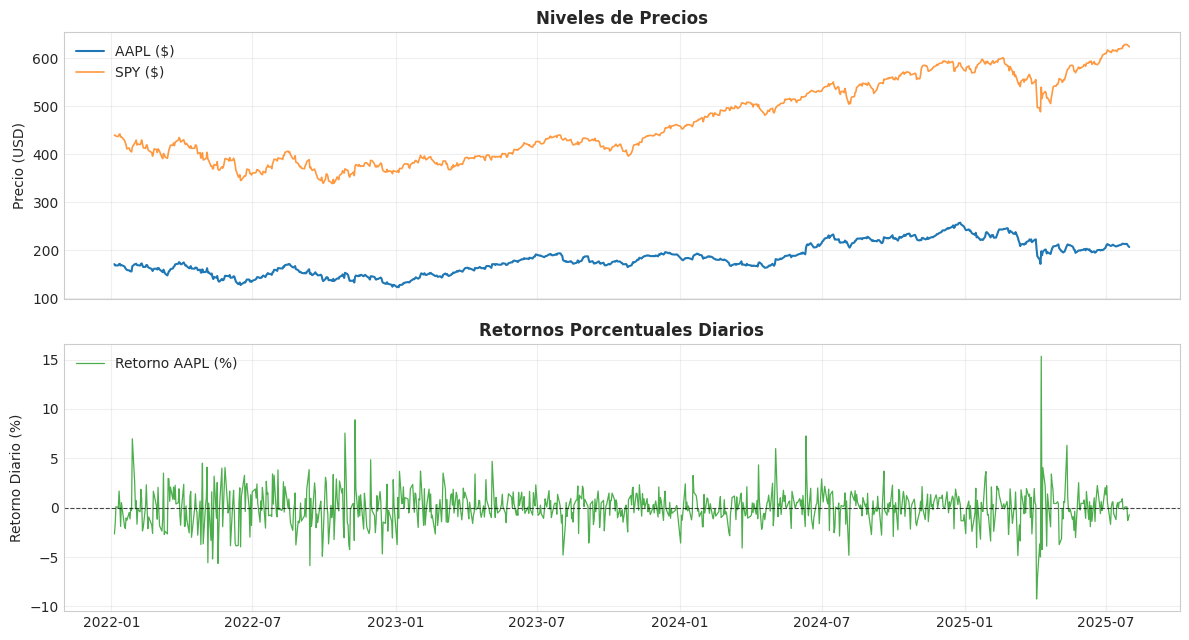

In [32]:
# Comparación gráfica: Precios en niveles (no estacionarios) vs. Retornos (estacionarios)
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)

# Panel 1: Precios en Niveles
axes[0].plot(df.index, df["Close_AAPL"], color="#1f77b4", lw=1.5, label="AAPL ($)")
axes[0].plot(df.index, df["Close_SPY"], color="#ff7f0e", lw=1.2, alpha=0.8, label="SPY ($)")
axes[0].set_title("Niveles de Precios", fontweight="bold")
axes[0].set_ylabel("Precio (USD)")
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)

# Panel 2: Retornos Porcentuales Diarios
axes[1].plot(df.index, df["Close_pct"], color="#2ca02c", lw=0.9, alpha=0.85, label="Retorno AAPL (%)")
axes[1].axhline(0, color="black", lw=0.8, linestyle="--", alpha=0.7)
axes[1].set_title("Retornos Porcentuales Diarios", fontweight="bold")
axes[1].set_ylabel("Retorno Diario (%)")
axes[1].legend(loc="upper left")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 2. Marco Teórico: Los 6 Supuestos Clásicos de la Regresión Lineal

Para que los estimadores de Mínimos Cuadrados Ordinarios (MCO / OLS) sean los mejores estimadores lineales insesgados (**MELI / BLUE**), deben cumplirse ciertos supuestos. En series de tiempo financieras, **casi todos se tensan o violan**:

| # | Supuesto | Definición Matemática | ¿Qué ocurre en Finanzas? | Consecuencia si se viola |
|---|---|---|---|---|
| **1** | **Linealidad en parámetros** | $Y = \alpha + \beta X + \varepsilon$ | Las relaciones pueden ser no lineales (asimetrías en caídas vs subidas). | Mala especificación del modelo. |
| **2** | **Exogeneidad estricta** | $\mathbb{E}[\varepsilon \mid X] = 0$ | Si hay variables omitidas (noticias, tasas de interés), el error se correlaciona con $X$. | **Sesgo en los coeficientes** $\beta$. |
| **3** | **Homocedasticidad** | $\text{Var}(\varepsilon_t) = \sigma^2$ cte. | En finanzas hay **clusters de volatilidad**: días de pánico tienen errores enormes. | Errores estándar erróneos $\rightarrow$ inferencia falsa. |
| **4** | **No autocorrelación** | $\text{Cov}(\varepsilon_t, \varepsilon_{t-1}) = 0$ | Si el mercado tiene inercia o microestructura, los errores se correlacionan en el tiempo. | Se subestima el riesgo y los p-values están inflados. |
| **5** | **Normalidad de errores** | $\varepsilon \sim \mathcal{N}(0, \sigma^2)$ | Los retornos tienen **colas pesadas (*fat tails*)** y eventos extremos frecuentes. | Intervalos de confianza basados en t de Student pierden validez exacta. |
| **6** | **No multicolinealidad** | $\text{det}(X'X) \neq 0$ | Si incluimos dos variables muy parecidas (ej. S&P500 y ETF de tecnología), se anulan. | Coeficientes inestables y con varianza gigante. |


In [44]:
retornos = df["Close_pct"].dropna()
mu, sigma = retornos.mean(), retornos.std()

# Tests formales de normalidad
jb_stat, jb_pval = jarque_bera(retornos)
print(f"  • Media diaria:           {retornos.mean():.4f}%")
print(f"  • Desviación estándar:    {retornos.std():.4f}%")
print(f"  • Asimetría (Skewness):   {skew(retornos):.4f} (Normal = 0)")
print(f"  • Curtosis excesiva:      {kurtosis(retornos):.4f} (Normal = 0; >0 indica colas pesadas)")
print(f"  • Test Jarque-Bera:       p-value = {jb_pval:.2e} -> Se {'RECHAZA' if jb_pval < 0.05 else 'ACEPTA'} normalidad.")

  • Media diaria:           0.0349%
  • Desviación estándar:    1.8359%
  • Asimetría (Skewness):   0.5471 (Normal = 0)
  • Curtosis excesiva:      7.4489 (Normal = 0; >0 indica colas pesadas)
  • Test Jarque-Bera:       p-value = 0.00e+00 -> Se RECHAZA normalidad.


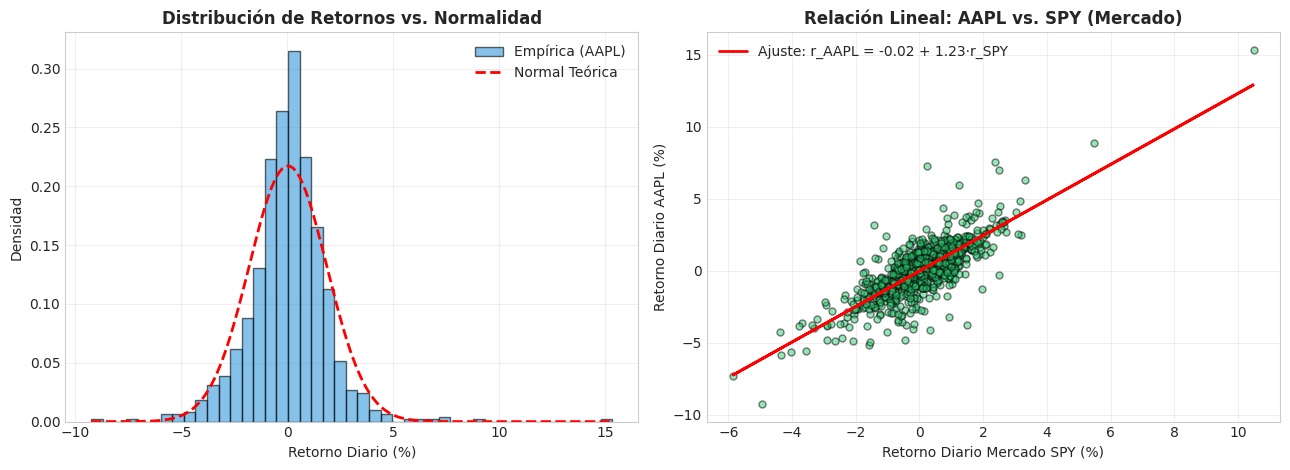

In [41]:
# Diagnóstico Visual y Estadístico de Supuestos: Normalidad y Asimetría
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# 1. Graficar distribucion Retoronos
x_norm = np.linspace(retornos.min(), retornos.max(), 200)
pdf_norm = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_norm - mu) / sigma)**2)

axes[0].hist(retornos, bins=45, density=True, color="#3498db", edgecolor="black", alpha=0.6, label="Empírica (AAPL)")
axes[0].plot(x_norm, pdf_norm, 'r--', lw=2, label="Normal Teórica")
axes[0].set_title("Distribución de Retornos vs. Normalidad", fontweight="bold")
axes[0].set_xlabel("Retorno Diario (%)")
axes[0].set_ylabel("Densidad")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Scatter Plot: Retorno AAPL vs. Retorno Mercado SPY
axes[1].scatter(df["Market_pct"], df["Close_pct"], alpha=0.5, color="#2ecc71", edgecolor="k", s=25)
coef_ols = np.polyfit(df["Market_pct"], df["Close_pct"], 1)
axes[1].plot(df["Market_pct"], np.poly1d(coef_ols)(df["Market_pct"]), color="red", lw=2,
             label=f"Ajuste: r_AAPL = {coef_ols[1]:.2f} + {coef_ols[0]:.2f}·r_SPY")
axes[1].set_title("Relación Lineal: AAPL vs. SPY (Mercado)", fontweight="bold")
axes[1].set_xlabel("Retorno Diario Mercado SPY (%)")
axes[1].set_ylabel("Retorno Diario AAPL (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 3. Estimación Econométrica: Regresión Simple y Múltiple

### 3.1 Regresión Lineal Simple: El Modelo CAPM
En finanzas, el modelo de valoración de activos de capital (**CAPM**) postula que el retorno de una acción se explica por el retorno del mercado:
$$r_{i,t} = \alpha + \beta r_{m,t} + \varepsilon_t$$

* **$\alpha$ (Alfa de Jensen):** Retorno propio del activo independiente del mercado (si $\alpha > 0$, genera valor anormal).
* **$\beta$ (Beta de mercado):** Sensibilidad o exposición al riesgo sistemático:
  * $\beta = 1$: Se mueve a la par del mercado.
  * $\beta > 1$: Activo más volátil y agresivo que el mercado (típico de empresas tecnológicas).
  * $\beta < 1$: Activo defensivo (servicios básicos, consumo esencial).
* **$R^2$:** Proporción de la varianza explicada por el mercado.


In [45]:
# Estimación de Regresión Simple (CAPM) con Statsmodels
y_simple = df["Close_pct"]

# Agrega constante (alpha)
X_simple = sm.add_constant(df["Market_pct"]) 
modelo_simple = sm.OLS(y_simple, X_simple).fit()

print(modelo_simple.summary())


                            OLS Regression Results                            
Dep. Variable:              Close_pct   R-squared:                       0.623
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     1473.
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          3.52e-191
Time:                        12:22:51   Log-Likelihood:                -1377.1
No. Observations:                 895   AIC:                             2758.
Df Residuals:                     893   BIC:                             2768.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0191      0.038     -0.505      0.6

### 3.2 Regresión Lineal Múltiple e Inferencia Robusta Newey-West (HAC)

Ahora incorporamos:
1. El **retorno del mercado ($r_{SPY, t}$)**.
2. La **variación del volumen de negociación ($Volume\_pct_t$)**.
3. El **rezago autorregresivo ($r_{AAPL, t-1}$)** para capturar memoria de corto plazo o reversión.

$$r_{AAPL, t} = \alpha + \beta_1 r_{SPY, t} + \beta_2 Volume\_pct_t + \phi r_{AAPL, t-1} + \varepsilon_t$$

#### Inferencia Robusta: Newey-West (HAC)
Dado que en series de tiempo hay heterocedasticidad y correlación temporal residual, los errores estándar clásicos de OLS pueden estar sesgados.
Statsmodels permite corregir esto mediante `cov_type="HAC"` con rezagos de corrección (`maxlags=5`):
* **No cambia los coeficientes $\beta$** (los estimadores puntuales son los mismos).
* **Corrige los errores estándar, los t-stats y los p-values**, evitando conclusiones falsas sobre qué variables son significativas.


In [48]:
# Definición de variables para la regresión múltiple
y_mult = df["Close_pct"]
X_mult = df[["Market_pct", "Volume_pct", "Close_pct_lag1"]]
X_mult_const = sm.add_constant(X_mult)

# 1. Estimación OLS estándar
modelo_mult_clasico = sm.OLS(y_mult, X_mult_const).fit()

# 2. Estimación OLS con Errores Estándar Robustos Newey-West (HAC)
modelo_mult_hac = sm.OLS(y_mult, X_mult_const).fit(cov_type="HAC", cov_kwds={"maxlags": 5})

# Comparación de Errores Estándar y p-values
comparacion_df = pd.DataFrame({
    "Coeficiente": modelo_mult_clasico.params,
    "SE Clásico": modelo_mult_clasico.bse,
    "p-value Clásico": modelo_mult_clasico.pvalues,
    "SE Newey-West": modelo_mult_hac.bse,
    "p-value Newey-West": modelo_mult_hac.pvalues
})
comparacion_df.round(4)


,Coeficiente,SE Clásico,p-value Clásico,SE Newey-West,p-value Newey-West
const,-0.0231,0.0380,0.5446,0.0352,0.5120
Market_pct,1.2369,0.0322,0.0000,0.0462,0.0000
Volume_pct,0.0006,0.0011,0.6187,0.0017,0.7369
Close_pct_lag1,0.0405,0.0206,0.0493,0.0200,0.0425


### 3.3 Diagnóstico de Autocorrelación de Errores (Durbin-Watson)

El estadístico de **Durbin-Watson** evalúa si los residuos presentan autocorrelación de primer orden:
$$DW \approx 2(1 - \hat{\rho})$$
* **$DW \approx 2.0$:** No hay evidencia de autocorrelación en los errores (ideal).
* **$DW < 1.5$:** Indicio de autocorrelación positiva persistente.
* **$DW > 2.5$:** Indicio de autocorrelación negativa (alternancia de signos).


In [49]:
dw_stat = durbin_watson(modelo_mult_clasico.resid)
print(f"Estadístico Durbin-Watson: {dw_stat:.4f}")
if 1.7 <= dw_stat <= 2.3:
    print("El estadístico está cerca de 2.0: No se detecta autocorrelación severa de primer orden.")
else:
    print("El estadístico se aleja de 2.0: Existe persistencia temporal en los residuos.")


Estadístico Durbin-Watson: 1.8944
El estadístico está cerca de 2.0: No se detecta autocorrelación severa de primer orden.


## 4. El Cambio de Paradigma: De "Explicar el Pasado" a "Pronosticar el Futuro"

En econometría tradicional, a menudo nos enseñan a mirar el **$R^2$ dentro de muestra** (*in-sample*). Sin embargo, en finanzas y machine learning:
> **El $R^2$ dentro de muestra es un pésimo indicador de capacidad predictiva.**
> Un modelo puede memorizar perfectamente el ruido del pasado (overfitting) y tener un $R^2$ alto, pero fracasar estrepitosamente mañana cuando llegue nueva información.

### La Regla de Oro: Separación Temporal Estricta (Train vs. Test)
En datos de corte transversal (como predecir el valor de una casa), se suele mezclar la muestra al azar con `train_test_split(shuffle=True)`.
**En finanzas temporales, esto está TERMINANTEMENTE PROHIBIDO.**
* Si mezclamos datos al azar, el modelo utilizará datos del futuro para predecir el pasado: este gravísimo error se llama **Look-Ahead Bias** (sesgo de anticipación).
* **Solución:** Cortamos la serie cronológicamente.
  * **Train (Entrenamiento):** Primeros $75\%$ de los días para estimar los parámetros.
  * **Test (Evaluación Fuera de Muestra):** Últimos $25\%$ de los días para probar si el modelo sabe pronosticar.


In [50]:
# División Cronológica Train / Test (75% / 25%)
split_ratio = 0.75
split_index = int(len(df) * split_ratio)

train_df = df.iloc[:split_index].copy()
test_df  = df.iloc[split_index:].copy()

print(f"Total de observaciones:       {len(df)}")
print(f"- Muestra Train (Entrenamiento): {len(train_df)} días ({train_df.index[0].date()} al {train_df.index[-1].date()})")
print(f"- Muestra Test  (Pronóstico OOS): {len(test_df)} días ({test_df.index[0].date()} al {test_df.index[-1].date()})")

Total de observaciones:       895
- Muestra Train (Entrenamiento): 671 días (2022-01-05 al 2024-09-06)
- Muestra Test  (Pronóstico OOS): 224 días (2024-09-09 al 2025-07-31)


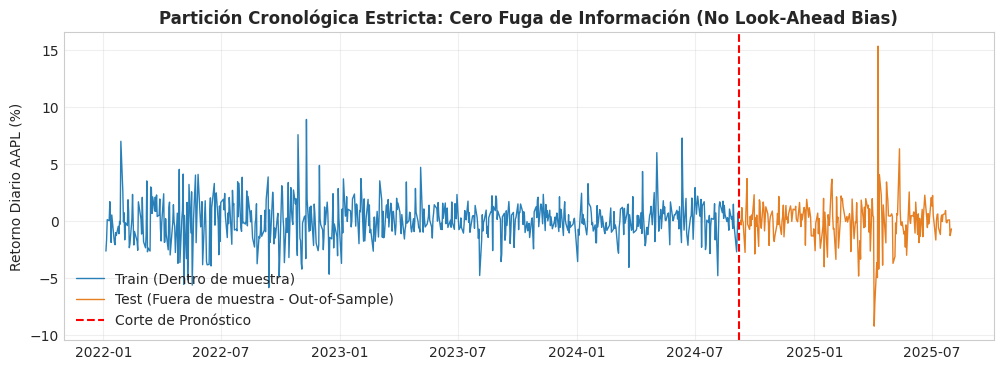

In [52]:
# Visualización de la partición en el tiempo
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train_df.index, train_df["Close_pct"], color="#2980b9", lw=1, label="Train (Dentro de muestra)")
ax.plot(test_df.index, test_df["Close_pct"], color="#e67e22", lw=1, label="Test (Fuera de muestra - Out-of-Sample)")
ax.axvline(train_df.index[-1], color="red", linestyle="--", lw=1.5, label="Corte de Pronóstico")
ax.set_title("Partición Cronológica Estricta: Cero Fuga de Información (No Look-Ahead Bias)", fontweight="bold")
ax.set_ylabel("Retorno Diario AAPL (%)")
ax.legend(loc="lower left")
ax.grid(True, alpha=0.3)
plt.show()


## 5. Esquemas de Pronóstico Temporal: Ventana Recursiva vs. Ventana Rodante

En la vida real, un analista o algoritmo financiero no pronostica una sola vez: **actualiza sus estimaciones a medida que pasan los días**.
Existen dos esquemas fundamentales para hacer pronósticos dinámicos un paso adelante (*one-step-ahead walk-forward*):

### 1. Ventana Recursiva (o Expansiva)
* **Cómo funciona:** La muestra de entrenamiento **crece** con cada nuevo día que se observa.
  * Paso 1: Entrena con $[1:T]$, pronostica el día $T+1$.
  * Paso 2: Entrena con $[1:T+1]$, pronostica el día $T+2$.
  * Paso 3: Entrena con $[1:T+2]$, pronostica el día $T+3$...
* **Ventaja:** Utiliza toda la historia acumulada; los coeficientes son más estables y menos sensibles al ruido de corto plazo.
* **Cuándo usar:** Si se asume que las relaciones económicas de largo plazo son estables.

### Esquema Gráfico Ventanas Recursiva:
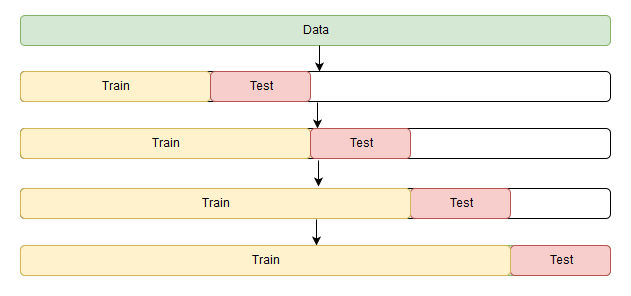

### 2. Ventana Rodante (*Rolling Window*)
* **Cómo funciona:** La muestra de entrenamiento mantiene un **tamaño fijo $W$** y se va desplazando en el tiempo descartando el dato más antiguo.
  * Paso 1: Entrena con $[1:W]$, pronostica $W+1$.
  * Paso 2: Entrena con $[2:W+1]$, pronostica $W+2$.
  * Paso 3: Entrena con $[3:W+2]$, pronostica $W+3$...
* **Ventaja:** Olvida el pasado remoto y **se adapta velozmente a cambios de régimen**, quiebres estructurales y crisis financieras.
* **Cuándo usar:** Mercados dinámicos con variaciones frecuentes de volatilidad o política monetaria.


### Esquema Gráfico Ventanas Rodantes:
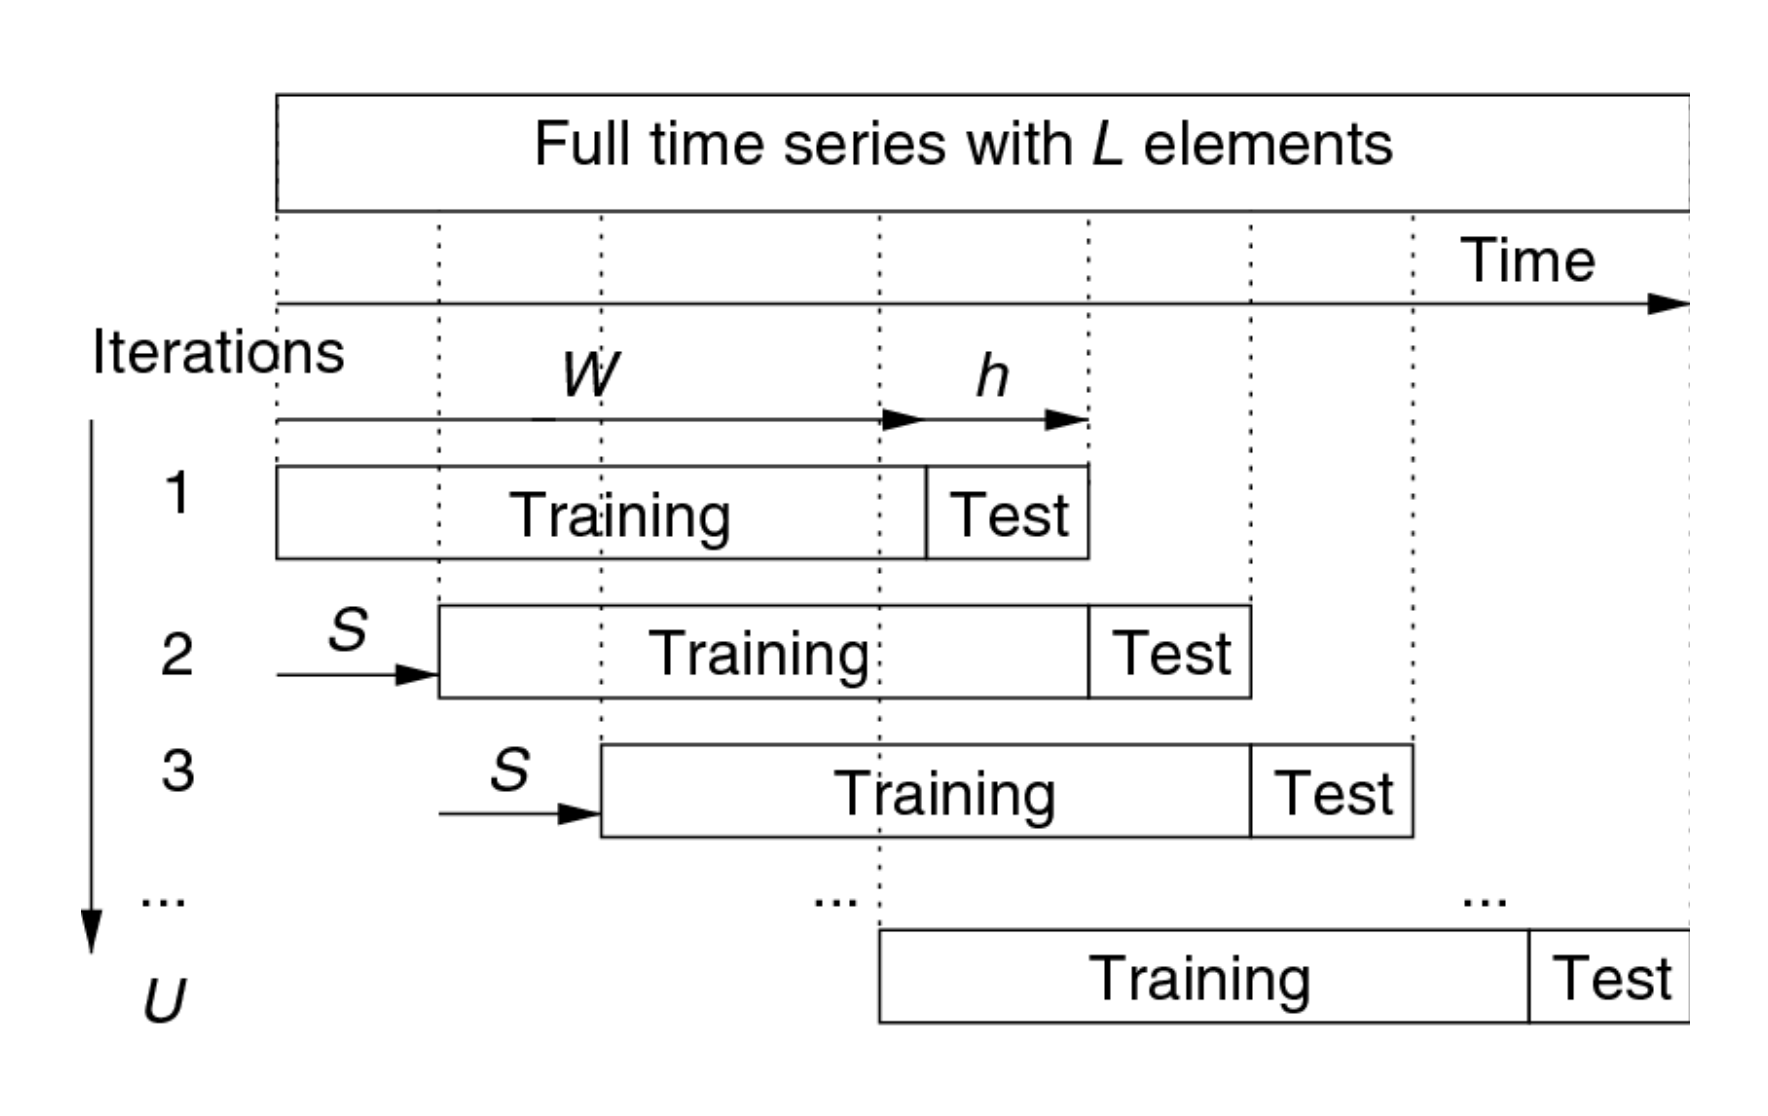

## 6. Métricas de Evaluación Fuera de Muestra y brenchmark

Para medir si un modelo realmente tiene capacidad predictiva (*predictive skill*), necesitamos métricas cuantitativas:

### 1. Error Cuadrático Medio (MSE) y RMSE
$$\text{RMSE} = \sqrt{\frac{1}{T_{test}} \sum_{t=1}^{T_{test}} (y_t - \hat{y}_t)^2}$$
* Expresa el error típico de pronóstico en las mismas unidades que la variable de estudio (en $\%$ de retorno diario).

### 2. El Benchmark Fundamental en Finanzas: El Paseo Aleatorio (*Random Walk*)
En machine learning tradicional, a veces se compara un modelo contra la media in-sample. Pero en Finanzas, según la **Hipótesis de los Mercados Eficientes (Fama)**, los retornos futuros son casi impredecibles:
* **El Benchmark ingenuo más difícil de vencer es predecir cero cambio (retorno esperado = 0) o la media histórica:**
$$\hat{y}_{t}^{\text{Benchmark}} = 0$$

### 3. El $R^2$ Fuera de Muestra ($R^2_{oos}$)
Definido por Campbell y Thompson (2008), compara el error cuadrático medio de nuestro modelo contra el error cuadrático del benchmark:
$$R^2_{oos} = 1 - \frac{\text{MSPE}_{\text{modelo}}}{\text{MSPE}_{\text{benchmark}}}$$

Donde $\text{MSPE} = \frac{1}{T} \sum (y_t - \hat{y}_t)^2$.

#### ¿Cómo se interpreta $R^2_{oos}$?
* **$R^2_{oos} > 0$:** El modelo tiene valor predictivo real y supera al azar/benchmark.
* **$R^2_{oos} = 0$:** El modelo es exactamente igual de bueno (o malo) que la regla ingenua.
* **$R^2_{oos} < 0$:** ¡El modelo destruye valor! Es peor que simplemente decir "el retorno será cero". El modelo memorizó ruido.


## 7. Implementación Práctica: Pronóstico Un Paso Adelante (*Walk-Forward*)

Vamos a realizar los dos esquemas predictivos sobre la muestra de Test:
1. **Modelo Recursivo (Expansivo):** Entrena con toda la historia disponible hasta $t-1$ y pronostica el retorno de AAPL en $t$.
2. **Modelo Rodante (*Rolling* de 120 días hábiles $\approx$ 6 meses):** Entrena con los 120 días más recientes y pronostica en $t$.
3. **Benchmark Random Walk:** Pronóstico base $\hat{y} = 0$.

> **Variables predictoras:** Retorno del mercado de hoy ($r_{SPY, t}$), variación del volumen ($Volume\_pct_t$) y rezago de ayer ($r_{AAPL, t-1}$).


In [66]:
# Preparar variables
feature_cols = ["Market_pct", "Volume_pct", "Close_pct_lag1"]
target_col   = "Close_pct"

# Listas para almacenar pronósticos y evolución de coeficientes
preds_recursivo = []
preds_rodante   = []
dates_test      = test_df.index
betas_mercado_recursivo = []
betas_mercado_rodante   = []

ventana_rolling = 120 # Ventana de 120 días hábiles (~6 meses)


In [67]:
for i in range(len(test_df)):
    current_idx = split_index + i
    current_date = df.index[current_idx]
    
    # 1. ESQUEMA RECURSIVO: Historial completo desde el inicio hasta current_idx - 1
    train_rec = df.iloc[:current_idx]
    X_train_rec = sm.add_constant(train_rec[feature_cols])
    y_train_rec = train_rec[target_col]
    
    # Ajustar modelo
    mod_rec = sm.OLS(y_train_rec, X_train_rec).fit()
    
    # Pronosticar el dato de hoy (current_idx)
    X_today = pd.DataFrame([df.iloc[current_idx][feature_cols]])
    X_today_const = sm.add_constant(X_today, has_constant='add')
    y_pred_rec = mod_rec.predict(X_today_const).iloc[0]
    preds_recursivo.append(y_pred_rec)
    betas_mercado_recursivo.append(mod_rec.params["Market_pct"])
    
    # 2. ESQUEMA RODANTE (ROLLING): Solo los últimos 'ventana_rolling' días
    start_roll = max(0, current_idx - ventana_rolling)
    train_roll = df.iloc[start_roll:current_idx]
    X_train_roll = sm.add_constant(train_roll[feature_cols])
    y_train_roll = train_roll[target_col]
    
    # Ajustar modelo
    mod_roll = sm.OLS(y_train_roll, X_train_roll).fit()
    
    # Pronosticar
    y_pred_roll = mod_roll.predict(X_today_const).iloc[0]
    preds_rodante.append(y_pred_roll)
    betas_mercado_rodante.append(mod_roll.params["Market_pct"])

# Consolidar resultados en un DataFrame de evaluación
eval_df = pd.DataFrame(index=dates_test)
eval_df["y_real"]            = test_df[target_col]
eval_df["pred_recursivo"]     = preds_recursivo
eval_df["pred_rodante"]       = preds_rodante
eval_df["pred_benchmark_rw"]  = 0.0 # Random walk: retorno esperado = 0

eval_df.head()


,y_real,pred_recursivo,pred_rodante,pred_benchmark_rw
Date,,,,
2024-09-09,0.040755,1.443728,1.641658,0.0
2024-09-10,-0.362132,0.495297,0.467131,0.0
2024-09-11,1.158516,1.228560,1.149417,0.0
2024-09-12,0.049395,1.033826,0.890852,0.0
2024-09-13,-0.121209,0.638374,0.678569,0.0


In [65]:
for i in range(len(test_df)):
    current_idx = split_index + i
    current_date = df.index[current_idx]
    
    # 1. ESQUEMA RECURSIVO: Historial completo desde el inicio hasta current_idx - 1
    train_rec = df.iloc[:current_idx]
    X_train_rec = sm.add_constant(train_rec[feature_cols])
    y_train_rec = train_rec[target_col]
    
    # Ajustar modelo
    mod_rec = sm.OLS(y_train_rec, X_train_rec).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    
    # Pronosticar el dato de hoy (current_idx)
    X_today = pd.DataFrame([df.iloc[current_idx][feature_cols]])
    X_today_const = sm.add_constant(X_today, has_constant='add')
    y_pred_rec = mod_rec.predict(X_today_const).iloc[0]
    preds_recursivo.append(y_pred_rec)
    betas_mercado_recursivo.append(mod_rec.params["Market_pct"])
    
    # 2. ESQUEMA RODANTE (ROLLING): Solo los últimos 'ventana_rolling' días
    start_roll = max(0, current_idx - ventana_rolling)
    train_roll = df.iloc[start_roll:current_idx]
    X_train_roll = sm.add_constant(train_roll[feature_cols])
    y_train_roll = train_roll[target_col]
    
    # Ajustar modelo
    mod_roll = sm.OLS(y_train_roll, X_train_roll).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    
    # Pronosticar
    y_pred_roll = mod_roll.predict(X_today_const).iloc[0]
    preds_rodante.append(y_pred_roll)
    betas_mercado_rodante.append(mod_roll.params["Market_pct"])

# Consolidar resultados en un DataFrame de evaluación
eval_df = pd.DataFrame(index=dates_test)
eval_df["y_real"]            = test_df[target_col]
eval_df["pred_recursivo"]     = preds_recursivo
eval_df["pred_rodante"]       = preds_rodante
eval_df["pred_benchmark_rw"]  = 0.0 # Random walk: retorno esperado = 0

eval_df.head()


,y_real,pred_recursivo,pred_rodante,pred_benchmark_rw
Date,,,,
2024-09-09,0.040755,1.443728,1.641658,0.0
2024-09-10,-0.362132,0.495297,0.467131,0.0
2024-09-11,1.158516,1.228560,1.149417,0.0
2024-09-12,0.049395,1.033826,0.890852,0.0
2024-09-13,-0.121209,0.638374,0.678569,0.0


### 7.1 Cálculo de Métricas y Comparativa de Desempeño Fuera de Muestra


In [68]:
# Función para calcular RMSE, MAE y R2 Fuera de Muestra (R2_OOS)
def calcular_metricas_oos(y_true, y_pred, y_bench):
    mspe_model = np.mean((y_true - y_pred)**2)
    mspe_bench = np.mean((y_true - y_bench)**2)
    
    rmse = np.sqrt(mspe_model)
    mae  = np.mean(np.abs(y_true - y_pred))
    r2_oos = 1.0 - (mspe_model / mspe_bench)
    
    return {
        "MSPE": mspe_model,
        "RMSE (%)": rmse,
        "MAE (%)": mae,
        "R2_OOS (%)": r2_oos * 100
    }

# Calcular métricas para cada modelo
metricas_rw   = calcular_metricas_oos(eval_df["y_real"], eval_df["pred_benchmark_rw"], eval_df["pred_benchmark_rw"])
metricas_rec  = calcular_metricas_oos(eval_df["y_real"], eval_df["pred_recursivo"], eval_df["pred_benchmark_rw"])
metricas_roll = calcular_metricas_oos(eval_df["y_real"], eval_df["pred_rodante"], eval_df["pred_benchmark_rw"])

# Tabla resumen
tabla_resumen = pd.DataFrame([
    {"Estrategia": "Benchmark: Random Walk (y_hat = 0)", **metricas_rw},
    {"Estrategia": "Regresión OLS Ventana Recursiva", **metricas_rec},
    {"Estrategia": "Regresión OLS Ventana Rodante (120d)", **metricas_roll}
]).set_index("Estrategia")

display(tabla_resumen.round(4))


,MSPE,RMSE (%),MAE (%),R2_OOS (%)
Estrategia,,,,
Benchmark: Random Walk (y_hat = 0),4.1877,2.0464,1.2812,0.0000
Regresión OLS Ventana Recursiva,1.6930,1.3011,0.9339,59.5734
Regresión OLS Ventana Rodante (120d),1.9009,1.3787,0.9560,54.6087


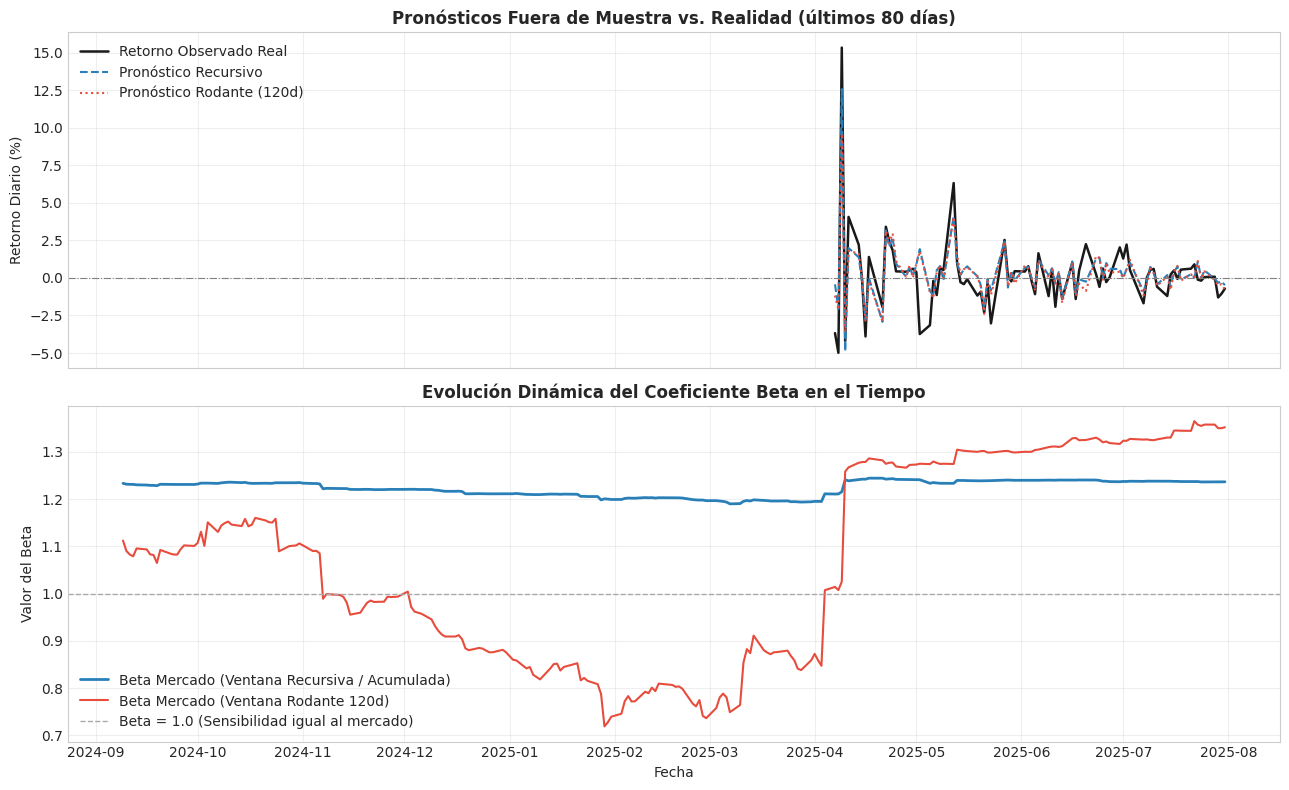

In [70]:
# Gráficos de Evaluación Predictiva
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# 1. Pronóstico vs Realidad (últimos 80 días de test para mayor nitidez)
zoom_days = 80
eval_zoom = eval_df.iloc[-zoom_days:]

axes[0].plot(eval_zoom.index, eval_zoom["y_real"], color="black", lw=1.8, label="Retorno Observado Real", alpha=0.9)
axes[0].plot(eval_zoom.index, eval_zoom["pred_recursivo"], color="#2980b9", lw=1.5, linestyle="--", label="Pronóstico Recursivo")
axes[0].plot(eval_zoom.index, eval_zoom["pred_rodante"], color="#e74c3c", lw=1.5, linestyle=":", label="Pronóstico Rodante (120d)")
axes[0].axhline(0, color="gray", lw=0.8, linestyle="-.")
axes[0].set_title(f"Pronósticos Fuera de Muestra vs. Realidad (últimos {zoom_days} días)", fontweight="bold")
axes[0].set_ylabel("Retorno Diario (%)")
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)

# 2. Evolución temporal del Coeficiente Beta de Mercado (Recursivo vs Rodante)
axes[1].plot(dates_test, betas_mercado_recursivo, color="#2980b9", lw=2, label="Beta Mercado (Ventana Recursiva / Acumulada)")
axes[1].plot(dates_test, betas_mercado_rodante, color="#e74c3c", lw=1.5, label="Beta Mercado (Ventana Rodante 120d)")
axes[1].axhline(1.0, color="darkgray", linestyle="--", lw=1, label="Beta = 1.0 (Sensibilidad igual al mercado)")
axes[1].set_title("Evolución Dinámica del Coeficiente Beta en el Tiempo", fontweight="bold")
axes[1].set_ylabel("Valor del Beta")
axes[1].set_xlabel("Fecha")
axes[1].legend(loc="lower left")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 8. Ejercicio 

### Instrucciones del Reto:
1. **Seleccionar una acción diferente** a Apple (por ejemplo: `MSFT`, `NVDA`, `AMZN`, `TSLA` o una chilena/latinoamericana si lo desean).
2. **Construir el modelo de regresión lineal múltiple** usando como predictores:
   * El retorno del mercado (`SPY`).
   * La componente autorregresiva (rezago del día anterior $r_{t-1}$).
3. **Ejecutar la validación predictiva fuera de muestra** con ventana recursiva.
4. **Calcular el $R^2_{oos}$** frente al Benchmark Random Walk.
5. **Responder las preguntas de reflexión financiera:**
   * ¿El $R^2_{oos}$ de tu acción fue positivo o negativo?
   * ¿Tiene sentido financiero el valor del $\beta$ obtenido? ¿La acción es defensiva o agresiva?
   * ¿Por qué el rezago $r_{t-1}$ suele tener un coeficiente cercano a cero en acciones muy líquidas? (investigar)


